# 01 · Fine-tuning del juez (Judgmental Llama / OLMo)

Reproduce la sección 3.1.3 del paper *Consensus vs. Dissent* (RecSys 2026): LoRA r=16, alpha=32, 4-bit NF4, lr 1e-4, batch 2 x grad. accum. 4, 4 epochs, mejor checkpoint por loss en el test original (262).

**Modo smoke:** con `SMOKE = True` entrena 20 pasos sobre 64 ejemplos (unos minutos) solo para comprobar que todo corre; el adaptador queda en `judgmental_<modelo>_smoke`. Cuando funcione, pon `SMOKE = False` para el entrenamiento real.

**Antes de empezar**
1. Sube a una carpeta de tu Drive: `finetune.py`, `train_v5_3.jsonl`, `test_v5_2.jsonl`.
2. Agrega el secret `HF_TOKEN` en Colab (icono de llave). Llama es *gated*: debes pedir acceso en su página de Hugging Face.
3. Runtime -> Change runtime type -> GPU (idealmente A100).

In [8]:
!pip install -q -U transformers peft trl datasets bitsandbytes accelerate scikit-learn

In [16]:
from google.colab import drive
drive.mount('/content/drive')

# ------------------------- CONFIGURACION -------------------------
PROJECT_DIR = '/content/drive/MyDrive/seminario_recsys'   # carpeta con finetune.py y los .jsonl
MODEL = 'olmo'                                      # 'olmo' o 'llama'
SMOKE = False                                       # True = prueba rapida (64 ejemplos, 20 pasos). False = entrenamiento real
LR = '1e-4'                                         # paper: 1e-4 (README del repo dice 2e-5 para OLMo)
OUT = f'/content/drive/MyDrive/judgmental_{MODEL}' + ('_smoke' if SMOKE else '')  # aqui quedan checkpoints y adaptador LoRA
# -----------------------------------------------------------------

import os
for f in ['finetune.py', 'train_v5_3.jsonl', 'test_v5_2.jsonl']:
    p = os.path.join(PROJECT_DIR, f)
    print(('OK      ' if os.path.exists(p) else 'FALTA   ') + p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK      /content/drive/MyDrive/seminario_recsys/finetune.py
OK      /content/drive/MyDrive/seminario_recsys/train_v5_3.jsonl
OK      /content/drive/MyDrive/seminario_recsys/test_v5_2.jsonl


In [17]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


In [ ]:
import os
os.environ.update(
    MODEL=MODEL,
    SMOKE='1' if SMOKE else '0',
    LEARNING_RATE=LR,
    OUTPUT_DIR=OUT,
    TRAIN_PATH=f'{PROJECT_DIR}/train_v5_3.jsonl',
    TEST_PATH=f'{PROJECT_DIR}/test_v5_2.jsonl',
)
# Revisa en la salida el 'MASKING SANITY CHECK': 'Unmasked' debe ser > 0.
!python {PROJECT_DIR}/finetune.py

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.
FINE-TUNING CONFIGURATION
Model: allenai/Olmo-3-7B-Instruct-SFT
Train data: /content/drive/MyDrive/seminario_recsys/train_v5_3.jsonl
Test data: /content/drive/MyDrive/seminario_recsys/test_v5_2.jsonl
Output: /content/drive/MyDrive/judgmental_olmo
Epochs: 4
Batch size: 2
Gradient accumulation: 4
Learning rate: 0.0001
LoRA r: 16, alpha: 32
LOADING DATASETS
Train examples: 5318
Test examples: 262

Sample train example:
{
  "messages": [
    {
      "role": "system",
      "content": "You are a participant in a scientific study. You will be presented with scenarios where a software system makes recommendations based on group preferences. Evaluate the fairness, consensus, and satisfaction using a 7-point Likert scale (-3 to 3).\n\nThe statements are to be answered using a 7-point Likert scale:\n-3: strongly disagree\n-2: disagree\n-1: somewhat disagree\n0: neither

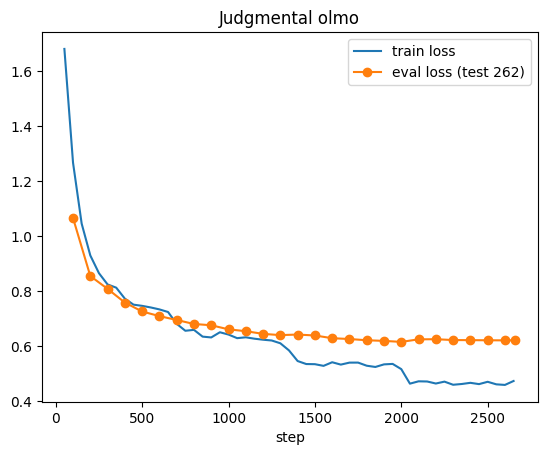

In [19]:
# Curva de loss desde el ultimo checkpoint guardado
import glob, json
import matplotlib.pyplot as plt

states = sorted(glob.glob(f'{OUT}/checkpoint-*/trainer_state.json'),
                key=lambda p: int(p.split('checkpoint-')[1].split('/')[0]))
log = json.load(open(states[-1]))['log_history']
tr = [(l['step'], l['loss']) for l in log if 'loss' in l]
ev = [(l['step'], l['eval_loss']) for l in log if 'eval_loss' in l]
plt.plot(*zip(*tr), label='train loss')
plt.plot(*zip(*ev), marker='o', label='eval loss (test 262)')
plt.xlabel('step'); plt.legend(); plt.title(f'Judgmental {MODEL}')
plt.show()

**Notas**
- El adaptador LoRA final queda en `OUT` (pesa poco). Ese directorio es el que usa el notebook 02.
- El script no reanuda entrenamientos: si Colab se desconecta, quedan los checkpoints en Drive pero habria que relanzar (o pasar `resume_from_checkpoint`).
- Tiempo: el paper no lo reporta. Mira el tiempo por step en la barra de progreso para estimar el total.